# 02 — Modelling: imbalance strategies × models, feature ablation, threshold tuning

**Protocol (identical for every configuration)**
- Target `machine_failure`; X = `type` + 5 process parameters (+ 3 physics features where stated).
  The failure-mode flags and IDs are removed in `src/data.get_X_y` (**leakage**, see notebook 01).
- Stratified 5-fold CV with a fixed seed. Every configuration sees **the same folds**, so per-fold
  differences are paired comparisons. Every metric is reported as mean ± std over the 5 folds.
- Any resampling sits **inside** an `imblearn` Pipeline, so it runs on training folds only (`src/pipeline.py`).
- Primary metric: **PR-AUC (average precision)**. Accuracy is shown but never used for selection (`src/cv.py`).
- Threshold-dependent metrics (F1, recall, precision, accuracy, confusion matrix) use the default
  0.5 cut-off unless a tuned threshold is stated explicitly.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from src.config import MODELS_DIR, RANDOM_STATE, REPORTS_DIR
from src.data import get_X_y
from src.pipeline import (MODELS, MODEL_NAMES, NEG_POS_RATIO, STRATEGIES, STRATEGY_NAMES,
                          build_pipeline)
from src.cv import (CV, METRICS, METRIC_NAMES, PRIMARY, fold_metrics, mean_std,
                    nested_threshold_cv, nested_tuning_cv, run_cv, threshold_for_f1,
                    threshold_for_recall)
from src import plots
from src.plots import INK_2, MUTED, SERIES, savefig

plots.set_style()
X, y = get_X_y()
PREVALENCE = y.mean()
assert np.isclose(NEG_POS_RATIO, (y == 0).sum() / (y == 1).sum())  # used for XGBoost scale_pos_weight
print("X:", X.shape, "| columns:", list(X.columns), f"| prevalence {PREVALENCE:.2%}")

X: (10000, 6) | columns: ['type', 'air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min'] | prevalence 3.39%


## 1. SMOTE really happens inside the fold

Fold 0 of the shared splitter, traced by hand through the same pipeline used in CV:

In [2]:
tr, te = next(CV.split(X, y))
pipe = build_pipeline("xgb", "smote")
print("pipeline steps:", [name for name, _ in pipe.steps])
Xt = pipe[:-2].fit_transform(X.iloc[tr])            # physics features + encoder/scaler fitted on the training fold only
Xr, yr = pipe.named_steps["smote"].fit_resample(Xt, y.iloc[tr])
print(f"training fold: {len(tr):,} rows, {y.iloc[tr].sum()} failures  ->  after SMOTENC: {len(Xr):,} rows, {int(yr.sum()):,} failures")
print(f"test fold    : {len(te):,} rows, {y.iloc[te].sum()} failures  (predict_proba never resamples)")
print("Type values in resampled data:", np.unique(Xr[:, 0]), "(SMOTENC keeps the category valid)")

pipeline steps: ['physics', 'prep', 'smote', 'clf']
training fold: 8,000 rows, 272 failures  ->  after SMOTENC: 15,456 rows, 7,728 failures
test fold    : 2,000 rows, 67 failures  (predict_proba never resamples)
Type values in resampled data: [0. 1. 2.] (SMOTENC keeps the category valid)


## 2. Full grid: 3 models × 3 imbalance strategies × {with, without} engineered features

18 configurations × 5 folds. Hyper-parameters are fixed, sensible defaults chosen *before* looking at
results (`src/pipeline.make_model`); tuning comes later, in §6.

In [3]:
results, oof = {}, {}
t0 = time.time()
for eng in (True, False):
    for m in MODELS:
        for s in STRATEGIES:
            r = run_cv(build_pipeline(m, s, engineered=eng), X, y)
            results[(m, s, eng)], oof[(m, s, eng)] = r.folds, r.oof
print(f"{len(results)} configurations x {CV.n_splits} folds in {time.time() - t0:.0f}s")

folds_long = pd.concat(
    [df.assign(model=m, strategy=s, engineered=e) for (m, s, e), df in results.items()], ignore_index=True)
folds_long.to_csv(REPORTS_DIR / "cv_folds.csv", index=False)

summary = (folds_long.groupby(["model", "strategy", "engineered"])[METRICS].agg(["mean", "std"]))
summary.columns = [f"{m}_{a}" for m, a in summary.columns]
summary.reset_index().to_csv(REPORTS_DIR / "cv_summary.csv", index=False)

def results_table(eng: bool) -> pd.DataFrame:
    t = pd.DataFrame({(MODEL_NAMES[m], STRATEGY_NAMES[s]): mean_std(results[(m, s, eng)])
                      for m in MODELS for s in STRATEGIES}).T
    t.columns = [METRIC_NAMES[c] for c in t.columns]
    return t

print("With engineered features (mean ± std over 5 folds, threshold 0.5):")
table_eng = results_table(True)
table_eng

18 configurations x 5 folds in 83s
With engineered features (mean ± std over 5 folds, threshold 0.5):


PR-AUC (primary)        ROC-AUC  \
Logistic Regression No resampling      0.495 ± 0.048  0.919 ± 0.007   
                    Class weighting    0.452 ± 0.050  0.928 ± 0.008   
                    SMOTE (in-fold)    0.431 ± 0.060  0.924 ± 0.009   
Random Forest       No resampling      0.905 ± 0.008  0.978 ± 0.004   
                    Class weighting    0.892 ± 0.014  0.977 ± 0.004   
                    SMOTE (in-fold)    0.878 ± 0.009  0.982 ± 0.003   
XGBoost             No resampling      0.872 ± 0.019  0.981 ± 0.005   
                    Class weighting    0.875 ± 0.017  0.981 ± 0.006   
                    SMOTE (in-fold)    0.872 ± 0.013  0.977 ± 0.003   

                                      F1 (failure)         Recall  \
Logistic Regression No resampling    0.353 ± 0.037  0.233 ± 0.030   
                    Class weighting  0.275 ± 0.012  0.850 ± 0.046   
                    SMOTE (in-fold)  0.278 ± 0.014  0.826 ± 0.033   
Random Forest       No resampling    0.886 ± 0.019  0.814 ± 0.027   
                    Class weighting  0.882 ± 0.037  0.832 ± 0.053   
                    SMOTE (in-fold)  0.761 ± 0.027  0.850 ± 0.046   
XGBoost             No resampling    0.828 ± 0.022  0.767 ± 0.051   
                    Class weighting  0.838 ± 0.014  0.832 ± 0.040   
                    SMOTE (in-fold)  0.755 ± 0.016  0.826 ± 0.026   

                                         Precision Accuracy (misleading)  
Logistic Regression No resampling    0.736 ± 0.083         0.971 ± 0.002  
                    Class weighting  0.164 ± 0.008         0.848 ± 0.008  
                    SMOTE (in-fold)  0.167 ± 0.009         0.854 ± 0.009  
Random Forest       No resampling    0.972 ± 0.010         0.993 ± 0.001  
                    Class weighting  0.941 ± 0.043         0.993 ± 0.002  
                    SMOTE (in-fold)  0.693 ± 0.055         0.982 ± 0.003  
XGBoost             No resampling    0.902 ± 0.037         0.989 ± 0.001  
                    Class weighting  0.848 ± 0.049         0.989 ± 0.001  
                    SMOTE (in-fold)  0.698 ± 0.044         0.982 ± 0.002

In [4]:
print("Without engineered features (raw 6 inputs):")
table_raw = results_table(False)
table_raw

Without engineered features (raw 6 inputs):


PR-AUC (primary)        ROC-AUC  \
Logistic Regression No resampling      0.463 ± 0.039  0.896 ± 0.010   
                    Class weighting    0.430 ± 0.055  0.901 ± 0.010   
                    SMOTE (in-fold)    0.418 ± 0.060  0.899 ± 0.008   
Random Forest       No resampling      0.795 ± 0.042  0.968 ± 0.007   
                    Class weighting    0.786 ± 0.037  0.969 ± 0.008   
                    SMOTE (in-fold)    0.736 ± 0.028  0.972 ± 0.004   
XGBoost             No resampling      0.794 ± 0.034  0.975 ± 0.006   
                    Class weighting    0.784 ± 0.037  0.975 ± 0.004   
                    SMOTE (in-fold)    0.786 ± 0.054  0.970 ± 0.003   

                                      F1 (failure)         Recall  \
Logistic Regression No resampling    0.288 ± 0.069  0.183 ± 0.055   
                    Class weighting  0.231 ± 0.005  0.802 ± 0.024   
                    SMOTE (in-fold)  0.240 ± 0.010  0.799 ± 0.016   
Random Forest       No resampling    0.713 ± 0.035  0.590 ± 0.050   
                    Class weighting  0.735 ± 0.041  0.637 ± 0.070   
                    SMOTE (in-fold)  0.623 ± 0.023  0.755 ± 0.063   
XGBoost             No resampling    0.712 ± 0.078  0.614 ± 0.101   
                    Class weighting  0.714 ± 0.030  0.773 ± 0.083   
                    SMOTE (in-fold)  0.635 ± 0.023  0.797 ± 0.070   

                                         Precision Accuracy (misleading)  
Logistic Regression No resampling    0.720 ± 0.114         0.970 ± 0.002  
                    Class weighting  0.135 ± 0.004         0.819 ± 0.010  
                    SMOTE (in-fold)  0.141 ± 0.007         0.828 ± 0.010  
Random Forest       No resampling    0.908 ± 0.041         0.984 ± 0.002  
                    Class weighting  0.877 ± 0.061         0.984 ± 0.002  
                    SMOTE (in-fold)  0.533 ± 0.042         0.969 ± 0.004  
XGBoost             No resampling    0.855 ± 0.047         0.983 ± 0.004  
                    Class weighting  0.669 ± 0.028         0.979 ± 0.001  
                    SMOTE (in-fold)  0.531 ± 0.040         0.969 ± 0.003

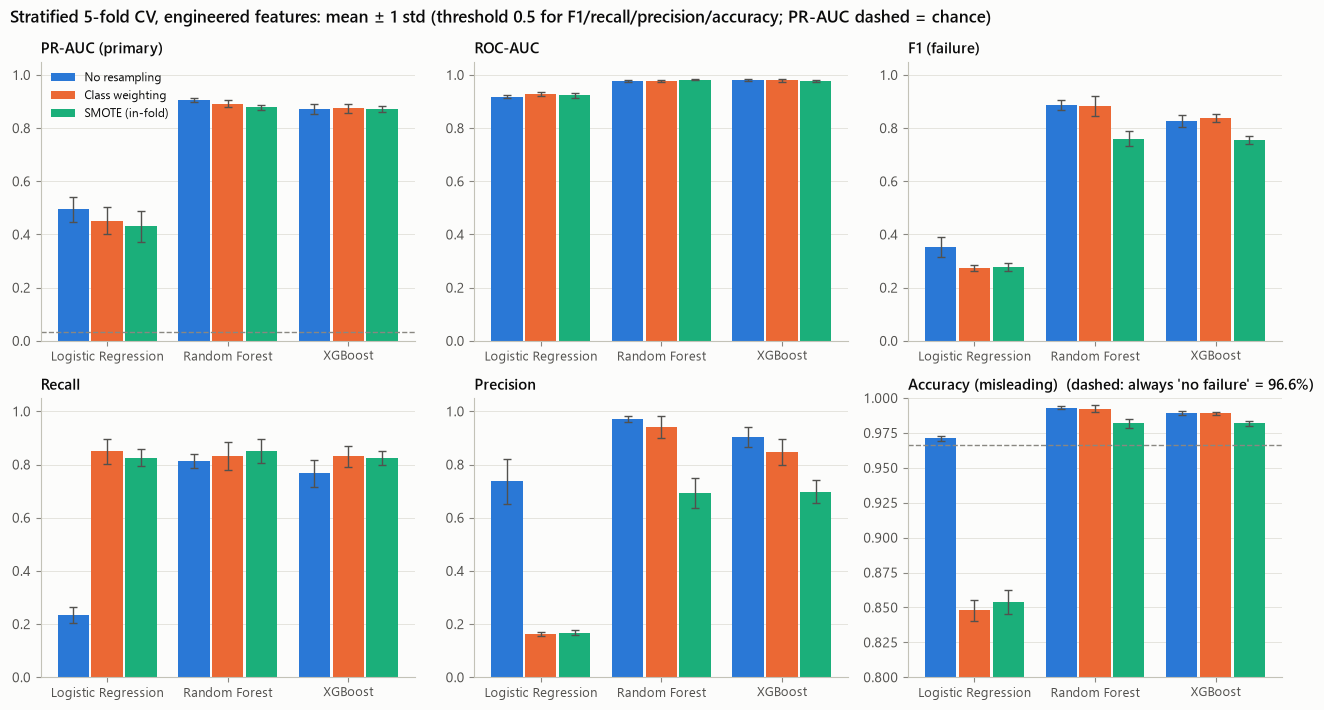

In [5]:
# CV-score comparison: grouped bars (model x strategy) with ±1 std error bars
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
w = 0.26
for ax, metric in zip(axes.flat, METRICS):
    for i, s in enumerate(STRATEGIES):
        means = [results[(m, s, True)][metric].mean() for m in MODELS]
        stds = [results[(m, s, True)][metric].std() for m in MODELS]
        xs = np.arange(len(MODELS)) + (i - 1) * (w + 0.02)
        ax.bar(xs, means, width=w, color=SERIES[i], label=STRATEGY_NAMES[s])
        ax.errorbar(xs, means, yerr=stds, fmt="none", ecolor=INK_2, elinewidth=1, capsize=3)
    ax.set_xticks(range(len(MODELS)), [MODEL_NAMES[m] for m in MODELS], fontsize=9)
    ax.set_title(METRIC_NAMES[metric], fontsize=11); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 1.05)
    if metric == "accuracy":
        ax.set_ylim(0.8, 1.0)
        ax.axhline(1 - PREVALENCE, color=MUTED, ls="--", lw=1)
        ax.set_title(f"{METRIC_NAMES[metric]}  (dashed: always 'no failure' = {1 - PREVALENCE:.1%})", fontsize=11)
    if metric == "pr_auc":
        ax.axhline(PREVALENCE, color=MUTED, ls="--", lw=1)
axes.flat[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Stratified 5-fold CV, engineered features: mean ± 1 std (threshold 0.5 for F1/recall/precision/accuracy; PR-AUC dashed = chance)",
             x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); savefig(fig, "06_cv_comparison"); plt.show()

**Reading the table**
- Look at PR-AUC first. Class weighting and SMOTE barely move the *ranking quality* of the tree models.
  What they mostly change is the **calibration**: they push probabilities upward, which trades precision
  for recall at the fixed 0.5 cut-off. The same trade can be bought more transparently by moving the
  threshold (§7). This is why threshold-dependent metrics at 0.5 do not compare fairly across strategies.
- ROC-AUC is ≥ 0.92 everywhere, including logistic regression, whose PR-AUC is only about 0.45–0.5.
  This is the imbalance problem in one picture: ROC-AUC hides poor precision on the rare class.
- Accuracy sits within about 3 points of the trivial 96.6% baseline for every model, so it carries no
  useful signal for selection.

## 3. Feature-engineering ablation (paired, same folds)

Δ = PR-AUC(with physics features) − PR-AUC(without), computed **per fold** and then averaged.
Because both runs use identical folds, the std of Δ is much tighter than either run's own std.

In [6]:
abl = []
for m in MODELS:
    for s in STRATEGIES:
        a, b = results[(m, s, True)][PRIMARY].values, results[(m, s, False)][PRIMARY].values
        d = a - b
        abl.append({"model": MODEL_NAMES[m], "strategy": STRATEGY_NAMES[s],
                    "PR-AUC without": f"{b.mean():.3f} ± {b.std(ddof=1):.3f}",
                    "PR-AUC with": f"{a.mean():.3f} ± {a.std(ddof=1):.3f}",
                    "delta_mean": d.mean(), "delta_std": d.std(ddof=1),
                    "folds improved": f"{(d > 0).sum()}/{len(d)}"})
ablation = pd.DataFrame(abl)
ablation.round(3)

,model,strategy,PR-AUC without,PR-AUC with,delta_mean,delta_std,folds improved
0,Logistic Regression,No resampling,0.463 ± 0.039,0.495 ± 0.048,0.032,0.020,5/5
1,Logistic Regression,Class weighting,0.430 ± 0.055,0.452 ± 0.050,0.021,0.024,4/5
2,Logistic Regression,SMOTE (in-fold),0.418 ± 0.060,0.431 ± 0.060,0.012,0.018,3/5
3,Random Forest,No resampling,0.795 ± 0.042,0.905 ± 0.008,0.110,0.038,5/5
4,Random Forest,Class weighting,0.786 ± 0.037,0.892 ± 0.014,0.106,0.029,5/5
5,Random Forest,SMOTE (in-fold),0.736 ± 0.028,0.878 ± 0.009,0.142,0.025,5/5
6,XGBoost,No resampling,0.794 ± 0.034,0.872 ± 0.019,0.078,0.029,5/5
7,XGBoost,Class weighting,0.784 ± 0.037,0.875 ± 0.017,0.091,0.035,5/5
8,XGBoost,SMOTE (in-fold),0.786 ± 0.054,0.872 ± 0.013,0.086,0.044,5/5


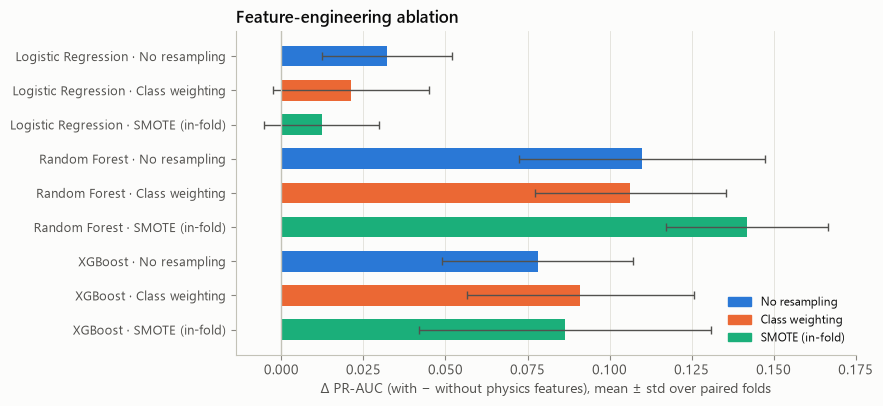

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = [f"{r.model} · {r.strategy}" for r in ablation.itertuples()]
ypos = np.arange(len(ablation))[::-1]
name_to_key = {v: k for k, v in STRATEGY_NAMES.items()}
colors = [SERIES[STRATEGIES.index(name_to_key[s])] for s in ablation.strategy]
ax.barh(ypos, ablation.delta_mean, xerr=ablation.delta_std, color=colors, height=0.6,
        error_kw=dict(ecolor=INK_2, elinewidth=1, capsize=3))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SERIES[i]) for i in range(len(STRATEGIES))],
          labels=[STRATEGY_NAMES[s] for s in STRATEGIES], loc="lower right", fontsize=8.5)
ax.axvline(0, color=plots.AXIS, lw=1)
ax.set_yticks(ypos, labels, fontsize=9); ax.grid(axis="y", visible=False)
ax.set_xlabel("Δ PR-AUC (with − without physics features), mean ± std over paired folds")
ax.set_title("Feature-engineering ablation")
savefig(fig, "07_feature_ablation"); plt.show()

## 4. PR and ROC curves (out-of-fold predictions, best strategy per model)

Every row's probability comes from the one model that **did not** train on it. Concatenating the 5
held-out folds therefore gives one honest prediction per machine run.

best strategy per model (by mean PR-AUC): {'logreg': 'none', 'rf': 'none', 'xgb': 'weighted'}


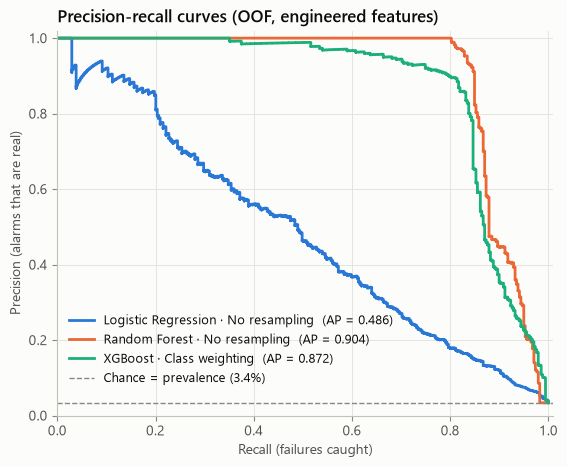

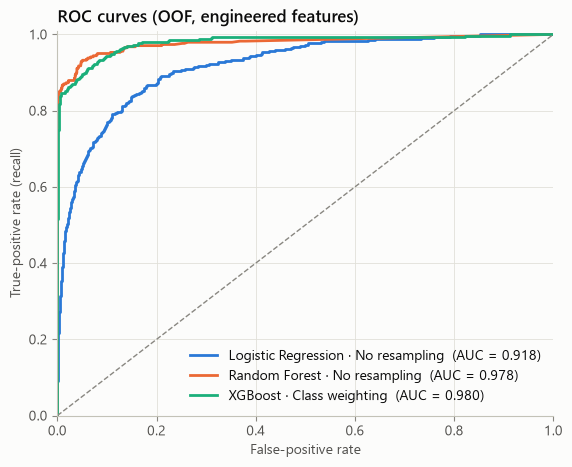

In [8]:
best_strategy = {m: max(STRATEGIES, key=lambda s: results[(m, s, True)][PRIMARY].mean()) for m in MODELS}
print("best strategy per model (by mean PR-AUC):", best_strategy)
curves = {f"{MODEL_NAMES[m]} · {STRATEGY_NAMES[s]}": oof[(m, s, True)] for m, s in best_strategy.items()}

fig, ax = plt.subplots(figsize=(6.4, 5))
plots.plot_pr_curves(ax, y, curves, prevalence=PREVALENCE)
ax.set_title("Precision-recall curves (OOF, engineered features)")
savefig(fig, "08_pr_curves"); plt.show()

fig, ax = plt.subplots(figsize=(6.4, 5))
plots.plot_roc_curves(ax, y, curves)
ax.set_title("ROC curves (OOF, engineered features)")
savefig(fig, "09_roc_curves"); plt.show()

## 5. Why SMOTE must stay inside the fold: a deliberate counter-example

Here we do it **wrong** on purpose: oversample the full dataset first, then cross-validate the same XGBoost.
Synthetic failures are interpolated between real failures, so near-copies of each test-fold failure sit
in the training folds, and the test folds themselves are about 50% synthetic positives.

In [9]:
prep = build_pipeline("xgb", "none")[:-1]          # physics + encoder/scaler (also fitted on all data: wrong, too)
X_all = pd.DataFrame(prep.fit_transform(X))
X_sm, y_sm = SMOTENC(categorical_features=[0], random_state=RANDOM_STATE).fit_resample(X_all, y)
clf = build_pipeline("xgb", "none").named_steps["clf"]
wrong = run_cv(clf, X_sm, pd.Series(y_sm))

leak_demo = pd.DataFrame({
    "SMOTE before split (WRONG)": mean_std(wrong.folds),
    "SMOTE inside fold (correct)": mean_std(results[("xgb", "smote", True)]),
}).T
leak_demo.columns = [METRIC_NAMES[c] for c in leak_demo.columns]
leak_demo

,PR-AUC (primary),ROC-AUC,F1 (failure),Recall,Precision,Accuracy (misleading)
SMOTE before split (WRONG),0.999 ± 0.000,0.999 ± 0.000,0.988 ± 0.003,0.991 ± 0.002,0.985 ± 0.005,0.988 ± 0.003
SMOTE inside fold (correct),0.872 ± 0.013,0.977 ± 0.003,0.755 ± 0.016,0.826 ± 0.026,0.698 ± 0.044,0.982 ± 0.002


The wrong protocol reports a near-perfect model. Its scores describe performance on a test set
that is half synthetic and leaks into training, not on real future machine runs.

## 6. Hyper-parameter tuning with **nested** CV (RF and XGBoost, same budget)

Inner: 3-fold randomized search (20 candidates, scored by average precision) on the outer-training part only.
Outer: the same 5 folds as above score whatever the inner search picked. The outer scores therefore
estimate the performance of the *whole procedure* (search + fit) without selection bias, and they are
directly comparable to the untuned grid. Each model is tuned under its best imbalance strategy from §2.
Runtime: ≈ 6 min (RF) + ≈ 20 min (XGBoost) on a laptop CPU; this is the slow cell of the notebook.
Logistic regression is not tuned: its PR-AUC gap (~0.4) is structural (the model is linear), not a
matter of regularisation strength.

In [10]:
SPACES = {
    "rf": {"clf__max_features": ["sqrt", 0.5, 0.8, 1.0], "clf__min_samples_leaf": [1, 2, 4, 8],
           "clf__max_depth": [None, 8, 16, 32]},
    "xgb": {"clf__n_estimators": randint(200, 900), "clf__learning_rate": loguniform(0.01, 0.2),
            "clf__max_depth": randint(3, 9), "clf__min_child_weight": randint(1, 8),
            "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.6, 0.4),
            "clf__gamma": uniform(0, 2)},
}
N_ITER = 20
tuned = {}
for m in ("rf", "xgb"):
    t0 = time.time()
    folds, chosen = nested_tuning_cv(build_pipeline(m, best_strategy[m]), SPACES[m], X, y, n_iter=N_ITER)
    tuned[m] = (folds, chosen)
    print(f"{MODEL_NAMES[m]} ({STRATEGY_NAMES[best_strategy[m]]}): nested PR-AUC "
          f"{folds.pr_auc.mean():.3f} ± {folds.pr_auc.std():.3f}  [{time.time() - t0:.0f}s]")
    for k, p in enumerate(chosen):
        print(f"   outer fold {k}: inner AP {folds.inner_best_pr_auc[k]:.3f} | outer AP {folds.pr_auc[k]:.3f} |",
              {kk.replace('clf__', ''): (round(float(v), 3) if isinstance(v, (float, np.floating)) else v) for kk, v in p.items()})

Random Forest (No resampling): nested PR-AUC 0.915 ± 0.006  [737s]
   outer fold 0: inner AP 0.911 | outer AP 0.915 | {'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 8}
   outer fold 1: inner AP 0.911 | outer AP 0.924 | {'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 8}
   outer fold 2: inner AP 0.911 | outer AP 0.913 | {'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 8}
   outer fold 3: inner AP 0.904 | outer AP 0.912 | {'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 8}
   outer fold 4: inner AP 0.912 | outer AP 0.908 | {'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 8}


XGBoost (Class weighting): nested PR-AUC 0.872 ± 0.022  [8332s]
   outer fold 0: inner AP 0.885 | outer AP 0.862 | {'colsample_bytree': 0.902, 'gamma': 0.458, 'learning_rate': 0.013, 'max_depth': 5, 'min_child_weight': 3, 'n_estimators': 285, 'subsample': 0.952}
   outer fold 1: inner AP 0.868 | outer AP 0.910 | {'colsample_bytree': 0.782, 'gamma': 1.57, 'learning_rate': 0.018, 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 330, 'subsample': 0.944}
   outer fold 2: inner AP 0.885 | outer AP 0.871 | {'colsample_bytree': 0.933, 'gamma': 0.425, 'learning_rate': 0.017, 'max_depth': 7, 'min_child_weight': 1, 'n_estimators': 659, 'subsample': 0.845}
   outer fold 3: inner AP 0.857 | outer AP 0.852 | {'colsample_bytree': 0.868, 'gamma': 1.332, 'learning_rate': 0.059, 'max_depth': 8, 'min_child_weight': 3, 'n_estimators': 746, 'subsample': 0.789}
   outer fold 4: inner AP 0.849 | outer AP 0.867 | {'colsample_bytree': 0.782, 'gamma': 1.57, 'learning_rate': 0.018, 'max_depth': 6, 'min_ch

## 7. Model selection

Candidates are every grid configuration (default hyper-parameters) plus the two nested-tuned procedures.
**Rule: highest mean PR-AUC.** Taking the max over ~20 candidates carries a little optimism of its
own, so the decisive question is whether the winner's lead exceeds the fold-to-fold noise. The paired
per-fold Δ below answers it.

In [11]:
cands = {}
for (m, s, e), df in results.items():
    cands[f"{MODEL_NAMES[m]} · {STRATEGY_NAMES[s]} · {'eng' if e else 'raw'} · default"] = (df, dict(model=m, strategy=s, engineered=e, tuned=False))
for m, (df, _) in tuned.items():
    cands[f"{MODEL_NAMES[m]} · {STRATEGY_NAMES[best_strategy[m]]} · eng · tuned (nested)"] = (df, dict(model=m, strategy=best_strategy[m], engineered=True, tuned=True))

leaderboard = pd.DataFrame({k: {"PR-AUC mean": v[0].pr_auc.mean(), "PR-AUC std": v[0].pr_auc.std(),
                               "ROC-AUC mean": v[0].roc_auc.mean()} for k, v in cands.items()}).T
leaderboard = leaderboard.sort_values("PR-AUC mean", ascending=False)
best_name = leaderboard.index[0]
best_folds, best_cfg = cands[best_name]
print("SELECTED:", best_name)

# Paired per-fold comparison of the winner vs the runner-up from each other model family
runner_rows = []
for m in MODELS:
    if m == best_cfg["model"]:
        continue
    other = next(n for n in leaderboard.index if cands[n][1]["model"] == m)
    d = best_folds.pr_auc.values - cands[other][0].pr_auc.values
    runner_rows.append({"vs": other, "Δ PR-AUC mean": d.mean(), "Δ std": d.std(ddof=1), "folds won": f"{(d > 0).sum()}/5"})
display(leaderboard.head(8).round(4))
pd.DataFrame(runner_rows).round(4)

SELECTED: Random Forest · No resampling · eng · tuned (nested)


,PR-AUC mean,PR-AUC std,ROC-AUC mean
Random Forest · No resampling · eng · tuned (nested),0.9146,0.0059,0.9783
Random Forest · No resampling · eng · default,0.9049,0.0078,0.9782
Random Forest · Class weighting · eng · default,0.8919,0.0136,0.9767
Random Forest · SMOTE (in-fold) · eng · default,0.8776,0.0086,0.9825
XGBoost · Class weighting · eng · default,0.8750,0.0171,0.9806
XGBoost · Class weighting · eng · tuned (nested),0.8724,0.0220,0.9829
XGBoost · SMOTE (in-fold) · eng · default,0.8721,0.0127,0.9767
XGBoost · No resampling · eng · default,0.8716,0.0189,0.9809


,vs,Δ PR-AUC mean,Δ std,folds won
0,Logistic Regression · No resampling · eng · de...,0.4196,0.0529,5/5
1,XGBoost · Class weighting · eng · default,0.0396,0.0145,5/5


## 8. Final hyper-parameters and out-of-fold predictions of the selected pipeline

If the winner is a tuned procedure, we rerun the same randomized search once on **all** data to get the
deployable hyper-parameters (standard practice: nested CV *estimates* the procedure, then the procedure is
applied to the full data). The OOF predictions below use those final parameters. Since the parameters
were chosen on all rows, these curves are very slightly optimistic; the headline numbers stay the nested ones.

In [12]:
m, s, e = best_cfg["model"], best_cfg["strategy"], best_cfg["engineered"]
final_params = {}
if best_cfg["tuned"]:
    search = RandomizedSearchCV(build_pipeline(m, s, e), SPACES[m], n_iter=N_ITER, scoring="average_precision",
                                cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                                random_state=RANDOM_STATE, n_jobs=1).fit(X, y)
    final_params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    final_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in final_params.items()}
print("final hyper-parameters:", final_params or "defaults (src/pipeline.make_model)")

final_pipe = build_pipeline(m, s, e, params=final_params)
final_cv = run_cv(final_pipe, X, y)
print("CV of final pipeline (threshold 0.5):"); print(mean_std(final_cv.folds).to_string())

final hyper-parameters: {'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 8}


CV of final pipeline (threshold 0.5):
pr_auc       0.915 ± 0.006
roc_auc      0.978 ± 0.007
f1           0.892 ± 0.017
recall       0.817 ± 0.026
precision    0.982 ± 0.017
accuracy     0.993 ± 0.001


## 9. Threshold tuning: favour recall, and show what it costs in precision

**Policy, fixed before looking at results:** in predictive maintenance a missed failure (unplanned downtime,
scrap, possible damage) costs far more than an extra inspection. So we choose the **highest threshold
that still catches ≥ 90% of failures**, which is the best precision available at that recall.

To estimate honestly how that threshold performs, the threshold itself is tuned inside each outer training
fold (via an inner 5-fold CV) and then applied to the untouched outer test fold (`nested_threshold_cv`).

In [13]:
TARGET_RECALL = 0.90
nested_thr = nested_threshold_cv(final_pipe, X, y, TARGET_RECALL)
print("thresholds chosen per outer fold:", nested_thr.threshold.round(3).tolist())

at_05 = mean_std(final_cv.folds)
at_tuned = mean_std(nested_thr)
thr_table = pd.DataFrame({"threshold 0.5 (default)": at_05,
                          f"tuned for recall ≥ {TARGET_RECALL:.0%} (nested)": at_tuned}).T
thr_table.columns = [METRIC_NAMES[c] for c in thr_table.columns]
display(thr_table)

# Deployable threshold: same rule applied to the OOF predictions of the full data
t_final = threshold_for_recall(y, final_cv.oof, TARGET_RECALL)
t_f1 = threshold_for_f1(y, final_cv.oof)
print(f"final threshold (recall >= {TARGET_RECALL:.0%} on full OOF): {t_final:.4f}   | F1-optimal threshold: {t_f1:.4f}")

thresholds chosen per outer fold: [0.052, 0.064, 0.054, 0.062, 0.055]


,PR-AUC (primary),ROC-AUC,F1 (failure),Recall,Precision,Accuracy (misleading)
threshold 0.5 (default),0.915 ± 0.006,0.978 ± 0.007,0.892 ± 0.017,0.817 ± 0.026,0.982 ± 0.017,0.993 ± 0.001
tuned for recall ≥ 90% (nested),0.915 ± 0.006,0.978 ± 0.007,0.658 ± 0.026,0.894 ± 0.016,0.522 ± 0.036,0.968 ± 0.004


final threshold (recall >= 90% on full OOF): 0.0559   | F1-optimal threshold: 0.4176


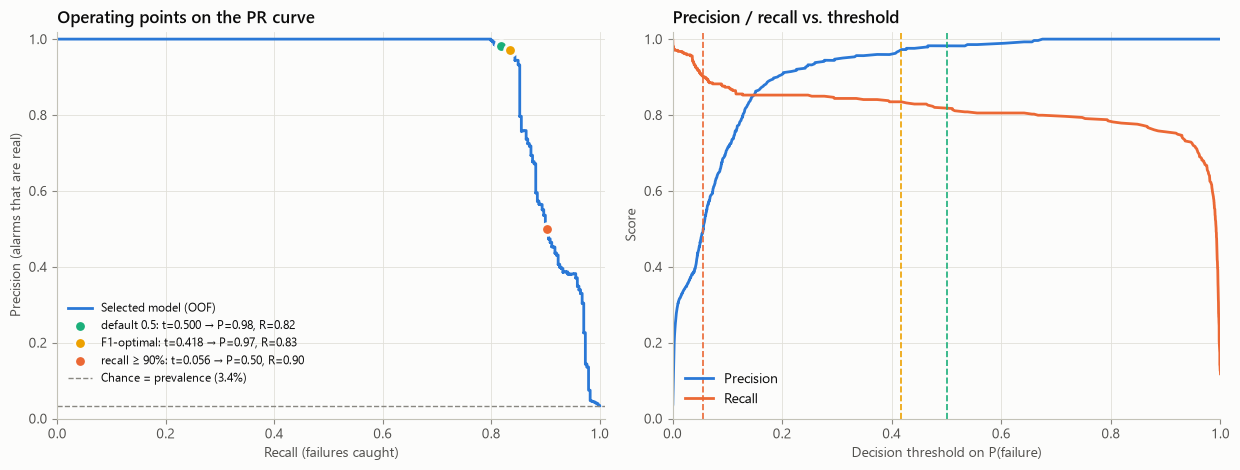

Moving the threshold 0.5 -> 0.056: recall 0.817 -> 0.903 (+0.086), precision 0.982 -> 0.500 (-0.482)


In [14]:
from sklearn.metrics import precision_recall_curve
prec, rec, thr = precision_recall_curve(y, final_cv.oof)
def point(t):
    pred = final_cv.oof >= t
    tp = (pred & (y == 1)).sum()
    return tp / max(pred.sum(), 1), tp / (y == 1).sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax1.step(rec, prec, where="post", color=SERIES[0], lw=2, label="Selected model (OOF)")
marks = [(0.5, "default 0.5", SERIES[2]), (t_f1, "F1-optimal", SERIES[3]), (t_final, f"recall ≥ {TARGET_RECALL:.0%}", SERIES[1])]
for t, lab, col in marks:
    p_, r_ = point(t)
    ax1.scatter([r_], [p_], s=70, color=col, edgecolor=plots.SURFACE, linewidth=2, zorder=5,
                label=f"{lab}: t={t:.3f} → P={p_:.2f}, R={r_:.2f}")
ax1.axhline(PREVALENCE, color=MUTED, ls="--", lw=1, label=f"Chance = prevalence ({PREVALENCE:.1%})")
ax1.set(xlim=(0, 1.01), ylim=(0, 1.02), xlabel="Recall (failures caught)", ylabel="Precision (alarms that are real)")
ax1.set_title("Operating points on the PR curve"); ax1.legend(loc="lower left", bbox_to_anchor=(0, 0.06), fontsize=8.5)

ax2.plot(thr, prec[:-1], color=SERIES[0], lw=2, label="Precision")
ax2.plot(thr, rec[:-1], color=SERIES[1], lw=2, label="Recall")
for t, lab, col in marks:
    ax2.axvline(t, color=col, lw=1.2, ls="--")
ax2.set(xlabel="Decision threshold on P(failure)", ylabel="Score", xlim=(0, 1), ylim=(0, 1.02))
ax2.set_title("Precision / recall vs. threshold"); ax2.legend(loc="lower left")
fig.tight_layout(); savefig(fig, "11_threshold_tradeoff"); plt.show()

p05, r05 = point(0.5); pt, rt = point(t_final)
print(f"Moving the threshold 0.5 -> {t_final:.3f}: recall {r05:.3f} -> {rt:.3f} (+{rt - r05:.3f}), "
      f"precision {p05:.3f} -> {pt:.3f} ({pt - p05:+.3f})")

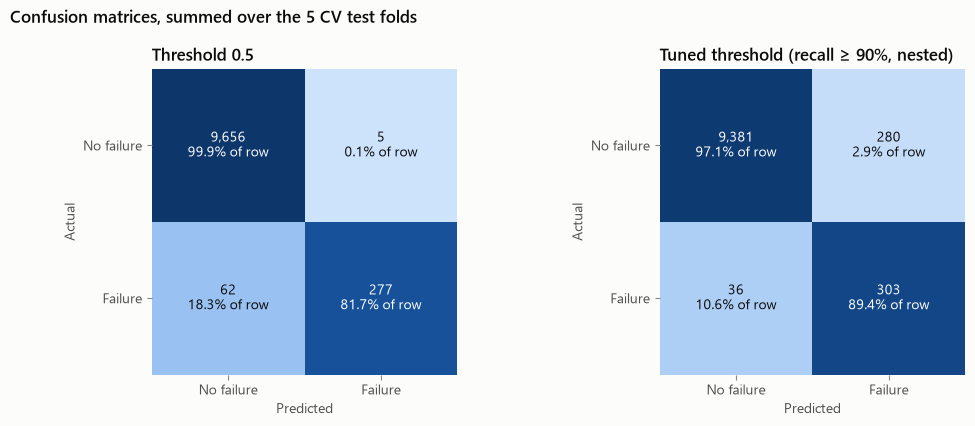

threshold 0.5   [[tn fp] [fn tp]] = [[9656, 5], [62, 277]]
tuned threshold [[tn fp] [fn tp]] = [[9381, 280], [36, 303]]


In [15]:
# Confusion matrices summed over the 5 outer test folds (each row counted once)
cm_05 = final_cv.folds[["tn", "fp", "fn", "tp"]].sum().values.reshape(2, 2)
cm_t = nested_thr[["tn", "fp", "fn", "tp"]].sum().values.reshape(2, 2)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
plots.plot_confusion(axes[0], cm_05, "Threshold 0.5")
plots.plot_confusion(axes[1], cm_t, f"Tuned threshold (recall ≥ {TARGET_RECALL:.0%}, nested)")
fig.suptitle("Confusion matrices, summed over the 5 CV test folds", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); savefig(fig, "10_confusion_matrix"); plt.show()
print("threshold 0.5   [[tn fp] [fn tp]] =", cm_05.tolist())
print("tuned threshold [[tn fp] [fn tp]] =", cm_t.tolist())

## 10. Fit the final model on all data and save artefacts for notebook 03 and the dashboard

In [16]:
final_model = build_pipeline(m, s, e, params=final_params).fit(X, y)
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(final_model, MODELS_DIR / "final_model.joblib", compress=3)

meta = {
    "selected": best_name, "model": m, "strategy": s, "engineered": bool(e), "tuned": best_cfg["tuned"],
    "hyperparameters": final_params, "threshold": t_final, "threshold_rule": f"highest threshold with OOF recall >= {TARGET_RECALL}",
    "target_recall": TARGET_RECALL, "f1_optimal_threshold": t_f1,
    "cv_headline_pr_auc": [float(best_folds.pr_auc.mean()), float(best_folds.pr_auc.std())],
    "metrics_at_0.5": {k: [float(final_cv.folds[k].mean()), float(final_cv.folds[k].std())] for k in METRICS},
    "metrics_at_tuned_threshold_nested": {k: [float(nested_thr[k].mean()), float(nested_thr[k].std())] for k in METRICS},
    "confusion_0.5": cm_05.tolist(), "confusion_tuned": cm_t.tolist(),
    "random_state": RANDOM_STATE, "n_splits": CV.n_splits,
}
(MODELS_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2))

oof_df = pd.DataFrame({"y": y.values, "final": final_cv.oof,
                       **{f"{m_}_{s_}": oof[(m_, s_, True)] for m_, s_ in best_strategy.items()}})
oof_df.to_csv(REPORTS_DIR / "oof_predictions.csv", index=False)
print(json.dumps({k: meta[k] for k in ("selected", "hyperparameters", "threshold")}, indent=2))

{
  "selected": "Random Forest \u00b7 No resampling \u00b7 eng \u00b7 tuned (nested)",
  "hyperparameters": {
    "min_samples_leaf": 2,
    "max_features": 0.8,
    "max_depth": 8
  },
  "threshold": 0.05593980394907975
}


## 11. Write `reports/metrics.md` (generated from the objects above, so it always matches this run)

In [17]:
def md_table(df: pd.DataFrame, index_name: str = "") -> str:
    df = df.copy()
    if isinstance(df.index, pd.MultiIndex):
        df.index = [" · ".join(map(str, i)) for i in df.index]
    head = "| " + " | ".join([index_name] + [str(c) for c in df.columns]) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    body = ["| " + " | ".join([str(i)] + [str(v) for v in row]) + " |" for i, row in zip(df.index, df.values)]
    return "\n".join([head, sep, *body])

abl_md = ablation.assign(**{"Δ PR-AUC (paired)": [f"{a:+.3f} ± {b:.3f}" for a, b in zip(ablation.delta_mean, ablation.delta_std)]})
abl_md = abl_md[["model", "strategy", "PR-AUC without", "PR-AUC with", "Δ PR-AUC (paired)", "folds improved"]].set_index(["model", "strategy"])
lb_md = leaderboard.head(8).apply(lambda r: pd.Series({"PR-AUC": f"{r['PR-AUC mean']:.3f} ± {r['PR-AUC std']:.3f}",
                                                       "ROC-AUC (mean)": f"{r['ROC-AUC mean']:.3f}"}), axis=1)
tuned_md = pd.DataFrame({f"{MODEL_NAMES[k]} (tuned, nested)": mean_std(v[0]) for k, v in tuned.items()}).T
tuned_md.columns = [METRIC_NAMES[c] for c in tuned_md.columns]
runner_md = pd.DataFrame(runner_rows).set_index("vs").round(4)
best_pr = best_folds.pr_auc
stable = best_cfg["tuned"] and all(c == tuned[best_cfg["model"]][1][0] for c in tuned[best_cfg["model"]][1])
bm, bs = best_cfg["model"], best_cfg["strategy"]
resampling_helped = any(results[(bm, s_, True)][PRIMARY].mean() > results[(bm, "none", True)][PRIMARY].mean()
                        for s_ in ("weighted", "smote"))
xgb_row = next(r for r in runner_rows if r["vs"].startswith("XGBoost")) if bm != "xgb" else None
lr_row = next(r for r in runner_rows if r["vs"].startswith("Logistic"))
d_tp, d_fp = cm_t[1, 1] - cm_05[1, 1], cm_t[0, 1] - cm_05[0, 1]
why_sel = "\n".join(f"- {b}" for b in [
    f"Highest mean PR-AUC of all {len(cands)} candidates.",
    (f"Beats the best XGBoost configuration on {xgb_row['folds won']} paired folds "
     f"(Δ PR-AUC {xgb_row['Δ PR-AUC mean']:+.3f} ± {xgb_row['Δ std']:.3f}), so the lead is larger than the fold noise." if xgb_row else ""),
    ("The inner search chose identical hyper-parameters in every outer fold, so the tuned configuration is stable."
     if stable else "Hyper-parameters chosen in the outer folds differ; see notebook §6."),
    ("No resampling: for this model neither class weighting nor SMOTE improved PR-AUC. They only shift the predicted "
     "probabilities, and the explicit threshold (§7) makes that trade more transparently." if not resampling_helped else
     f"Imbalance strategy `{bs}` gave the best PR-AUC for this model."),
    f"Logistic regression trails by ≈ {lr_row['Δ PR-AUC mean']:.2f} PR-AUC: the failure boundaries are non-linear "
    "(thresholds on products such as power and strain).",
] if b)

text = f'''# Metrics: AI4I 2020 machine-failure prediction

_Generated by `notebooks/02_modeling.ipynb`. Do not edit by hand; re-run the notebook._

**Data:** 10,000 runs, {int(y.sum())} failures (**{PREVALENCE:.2%}**, imbalance {NEG_POS_RATIO:.1f} : 1).
**Features:** `type` (ordinal L<M<H) plus 5 process parameters, plus 3 physics features where marked "eng".
Failure-mode flags (`TWF, HDF, PWF, OSF, RNF`) and IDs are excluded (**leakage**).
**Protocol:** stratified 5-fold CV (seed {RANDOM_STATE}), identical folds for every row in every table,
mean ± std over folds. Resampling (SMOTENC) happens **inside each training fold only** (imblearn Pipeline).
**Primary metric: PR-AUC** (average precision). Chance level = prevalence = {PREVALENCE:.3f}.
F1 / recall / precision / accuracy are at threshold 0.5 unless stated otherwise.
**Accuracy is misleading here:** always predicting "no failure" already scores {1 - PREVALENCE:.1%}.

## 1. Model × imbalance strategy (with engineered features)

{md_table(table_eng, "Model · strategy")}

## 2. Model × imbalance strategy (raw features only)

{md_table(table_raw, "Model · strategy")}

## 3. Feature-engineering ablation (paired per-fold Δ PR-AUC)

{md_table(abl_md, "Model · strategy")}

## 4. Hyper-parameter tuning (nested CV: inner 3-fold randomized search, {N_ITER} candidates; outer = same 5 folds)

{md_table(tuned_md, "Procedure")}

## 5. Leaderboard (top 8 by mean PR-AUC)

{md_table(lb_md, "Candidate")}

Paired per-fold comparison of the winner against the best candidate from each other model family:

{md_table(runner_md, "Winner vs")}

## 6. Selected model

**{best_name}**: PR-AUC **{best_pr.mean():.3f} ± {best_pr.std():.3f}**.
Final hyper-parameters: `{final_params or 'defaults from src/pipeline.make_model'}`.

**Why this model**

{why_sel}

## 7. Operating threshold

Rule (fixed before looking at results): highest threshold that keeps recall ≥ {TARGET_RECALL:.0%}, i.e. the best
precision at that recall. A missed failure costs far more than an extra inspection.
Deployed threshold (rule applied to full-data OOF predictions): **{t_final:.4f}** (F1-optimal would be {t_f1:.4f}).
Metrics at the tuned threshold come from **nested** CV: the threshold is chosen inside each outer training fold,
then scored on the untouched outer test fold.

{md_table(thr_table, "Operating point")}

**What the threshold buys and costs (summed over the 5 test folds):** moving from 0.5 to the tuned threshold catches
**{d_tp} more failures** ({cm_05[1, 1]} → {cm_t[1, 1]} of {int(y.sum())}) at the cost of **{d_fp} more false alarms**
({cm_05[0, 1]} → {cm_t[0, 1]}, i.e. {cm_t[0, 1] / cm_t[0].sum():.1%} of healthy runs flagged). Precision drops from
{final_cv.folds.precision.mean():.2f} to {nested_thr.precision.mean():.2f}: roughly one alarm in two is real. The PR curve
(`11_threshold_tradeoff.png`) has its knee at about 0.85 recall; past that, every extra failure caught costs many more
false alarms. If inspections are expensive, a lower recall target is defensible. The rule is one constant
(`TARGET_RECALL`) in the notebook.
Accuracy *falls* ({final_cv.folds.accuracy.mean():.3f} → {nested_thr.accuracy.mean():.3f}) while the model gets better at
its actual job of catching failures, which is one more reason accuracy is not used for selection.

Confusion matrices summed over the 5 test folds, `[[TN, FP], [FN, TP]]`:
- threshold 0.5: `{cm_05.tolist()}`
- tuned threshold: `{cm_t.tolist()}`

Figures: `reports/figures/06_cv_comparison.png`, `07_feature_ablation.png`, `08_pr_curves.png`, `09_roc_curves.png`,
`10_confusion_matrix.png`, `11_threshold_tradeoff.png`.
'''
(REPORTS_DIR / "metrics.md").write_text(text, encoding="utf-8")
print(text[:1500])

# Metrics: AI4I 2020 machine-failure prediction

_Generated by `notebooks/02_modeling.ipynb`. Do not edit by hand; re-run the notebook._

**Data:** 10,000 runs, 339 failures (**3.39%**, imbalance 28.5 : 1).
**Features:** `type` (ordinal L<M<H) plus 5 process parameters, plus 3 physics features where marked "eng".
Failure-mode flags (`TWF, HDF, PWF, OSF, RNF`) and IDs are excluded (**leakage**).
**Protocol:** stratified 5-fold CV (seed 42), identical folds for every row in every table,
mean ± std over folds. Resampling (SMOTENC) happens **inside each training fold only** (imblearn Pipeline).
**Primary metric: PR-AUC** (average precision). Chance level = prevalence = 0.034.
F1 / recall / precision / accuracy are at threshold 0.5 unless stated otherwise.
**Accuracy is misleading here:** always predicting "no failure" already scores 96.6%.

## 1. Model × imbalance strategy (with engineered features)

| Model · strategy | PR-AUC (primary) | ROC-AUC | F1 (failure) | Recall | Precision | Accu

## 12. Summary

**Selected:** Random Forest with physics features, no resampling, tuned (`max_depth=8, max_features=0.8,
min_samples_leaf=2`, 400 trees). Nested-CV **PR-AUC 0.915 ± 0.006** (ROC-AUC 0.978), against a chance level of 0.034.

| Finding | Evidence |
|---|---|
| Trees ≫ linear | LR PR-AUC ≈ 0.50 vs RF ≈ 0.91. The same ROC-AUC gap is only 0.92 vs 0.98, so ROC hides it |
| RF > XGBoost here | +0.040 ± 0.014 PR-AUC, RF wins 5/5 paired folds |
| Physics features help a lot | +0.08 to +0.14 PR-AUC for every tree config, 5/5 folds each. Axis-aligned splits approximate a product (power, strain) boundary only with many steps |
| Imbalance handling does **not** raise PR-AUC | RF: none 0.905, weighting 0.892, SMOTE 0.878. Weighting/SMOTE shift probabilities, buying recall at 0.5 with precision. Same trade as the threshold, but less transparent |
| SMOTE before split is badly wrong | 0.999 PR-AUC (fake) vs 0.872 done correctly |
| Tuning: modest, and nested CV matters | RF +0.010 with identical params in all 5 outer folds. XGBoost tuning did not help (0.872 vs 0.875) even though inner scores looked better, which is the selection optimism nested CV exists to expose |
| Threshold 0.5 | recall 0.817, precision 0.982 (62 failures missed, 5 false alarms) |
| Threshold ≈ 0.056 (recall ≥ 90%, nested) | recall 0.894 ± 0.016, precision 0.522 ± 0.036 (36 missed, 280 false alarms). Catching 26 more failures costs 275 more inspections; threshold stable at 0.052–0.064 across folds |

Next (notebook 03): SHAP explanations of this model, and risk surfaces / operating ranges per `Type`.